# Transfer to GP2–GP4: three-interval thixotropy test, Fig. 10

For compositions without SAOS/LAOS training data, eq. (9) is assembled from

* **linear coefficients** $c_1, c_2$: the GP1 age profile (Table 3) rescaled to pass through one
  calibration point from the linear range of the amplitude sweep (`08a_lve_single_point`);
* **nonlinear coefficients** $c_3$–$c_6$: the composition network (`08b_coefficient_network`);
* **critical stress** from eq. (8) with $\sigma_{cr}, t_{cr}$ of the amplitude sweep (`00_amplitude_sweeps`).

The pre-shear and the three 3ITT intervals are then simulated and $G'(t)$ is compared with the
measurements.

* **Inputs:** `results/coefficients/GP1_SAOS.csv`, `results/critical_points.csv`,
  `results/other_gps/GP*_LAOS_network.csv`, `data/3ITT_GP1-GP5.xlsx`
* **Output:** `figures/fig10_3ITT_GP2-GP4.png`

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rhinn_sindy import thixotropy as th
from rhinn_sindy.coefficients import load_saos_coefficients
from rhinn_sindy.paths import RESULTS_DIR
from rhinn_sindy.plotting import save_figure

TARGETS = ["GP2", "GP3", "GP4"]
COLORS = {"GP2": "#1f77b4", "GP3": "#ff7f0e", "GP4": "#2ca02c"}

## Settings

**Calibration points.** `ANCHORS` holds the linear-regime point of each composition used for Fig. 10:
the sample age `t_ref` (amplitude-sweep clock, s) and stress `sigma_lve` used for that age, and the
$c_1, c_2$ from the single-point training of `08a_lve_single_point` (rounded as entered):

| | training row | $c_1, c_2$ from that row | used for `t_ref`, `sigma_lve` |
|---|---|---|---|
| GP2 | 12 | −0.0323, 0.00384 (entered as +0.028, 0.0035) | t = 450 s (no matching row), row 0 |
| GP3 | 10 | −0.0052, 0.00069 | row 10 |
| GP4 | 2  | −0.00042, 7.1e-5 | row 12 |

$c_1 = 1/\eta$ should be positive. The training returns $c_1 < 0$ because the strain waveform was
built *leading* the stress (`rhinn_sindy.lve.lve_waveform`); `08a` shows the closed-form check.

`REPRODUCE_PAPER = True` repeats Fig. 10 as published:

1. the sign of every $c_1$ anchor is flipped; this makes GP3 and GP4 positive but GP2 negative;
2. $\sigma_{cr}$ of GP3 is 870.449 Pa, which is the storage modulus at the transition row
   (the stress there is 0.252 Pa, see `results/critical_points.csv`).

`False` uses $|c_1|$ and the stress at the transition row.

In [2]:
REPRODUCE_PAPER = True

ANCHORS = pd.DataFrame({
    "material":  ["GP2", "GP3", "GP4"],
    "t_ref":     [450.0, 493.971, 506.447],
    "sigma_lve": [0.01, 0.100227, 0.1585],
    "c1":        [0.028, -0.005, -0.00042254],
    "c2":        [0.0035, 0.00068, 7.096093e-05],
}).set_index("material")

T_GRID = np.arange(0.0, 751.0, 1.0)

## Coefficients along the protocol

The GP1 reference profile is Table 3 (`results/coefficients/GP1_SAOS.csv`). The pre-shear response
is sensitive to these values; the unrounded ones in `identified/` give a visibly different
pre-shear segment.

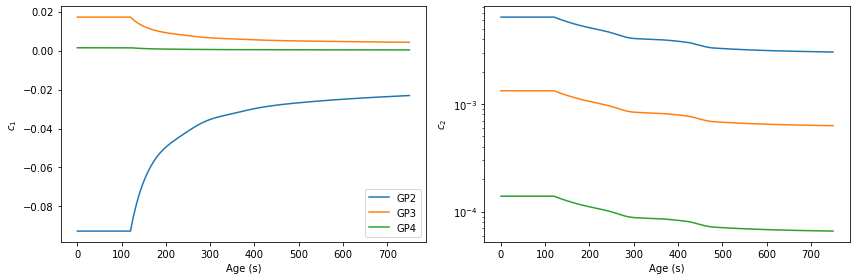

In [3]:
critical = pd.read_csv(RESULTS_DIR / "critical_points.csv", index_col="material")
gp1 = load_saos_coefficients("GP1")
ref_ages = gp1["age_min"].to_numpy() * 60.0

models = {}
for gp in TARGETS:
    a = ANCHORS.loc[gp]
    c1_anchor = -a["c1"] if REPRODUCE_PAPER else abs(a["c1"])
    c1s, c2s = th.scaled_saos_curves(ref_ages, gp1["c1"], gp1["c2"],
                                     a["t_ref"], c1_anchor, a["c2"], T_GRID)
    laos = pd.read_csv(RESULTS_DIR / "other_gps" / f"{gp}_LAOS_network.csv")
    sigma_cr = critical.loc[gp, "sigma_cr" if REPRODUCE_PAPER else "stress_at_row"]
    models[gp] = th.CompositionModel(
        T_GRID, {"c1s": c1s, "c2s": c2s, **{c: laos[c].to_numpy() for c in ["c3", "c4", "c5", "c6"]}},
        sigma_cr, critical.loc[gp, "t_cr"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for gp, m in models.items():
    axes[0].plot(T_GRID, m.coeffs["c1s"], color=COLORS[gp], label=gp)
    axes[1].plot(T_GRID, m.coeffs["c2s"], color=COLORS[gp])
axes[0].set(xlabel="Age (s)", ylabel="$c_1$")
axes[1].set(xlabel="Age (s)", ylabel="$c_2$", yscale="log")
axes[0].legend()
fig.tight_layout()
plt.show()

## Simulate and compare (Fig. 10)

In [4]:
simulated = {gp: th.simulate_3itt_transfer(models[gp], ANCHORS.loc[gp, "sigma_lve"]) for gp in TARGETS}
measured = {gp: th.load_3itt_storage_modulus(gp) for gp in TARGETS}

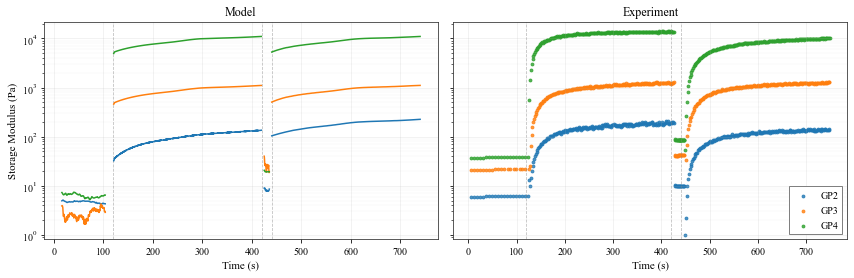

In [5]:
style = {"font.family": "serif", "font.serif": ["Times New Roman"], "font.size": 11,
         "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
         "ytick.labelsize": 10, "legend.fontsize": 10, "axes.linewidth": 0.8,
         "axes.edgecolor": "#333333", "mathtext.fontset": "stix"}
with mpl.rc_context(style):
    fig, (ax_m, ax_e) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for ax in (ax_m, ax_e):
        ax.set_yscale("log")
        ax.set_xlabel("Time (s)")
        ax.grid(True, which="major", lw=0.5, alpha=0.3)
        ax.grid(True, which="minor", lw=0.3, alpha=0.2)
        for x in (120.0, 420.0, 440.0):
            ax.axvline(x, color="gray", lw=0.8, ls="--", alpha=0.5)
    for gp in TARGETS:
        for i, (t, G) in enumerate(simulated[gp]):
            ax_m.plot(t, np.clip(G, 1e-3, None), color=COLORS[gp], lw=1.5, label=gp if i == 0 else "_")
        for i, (t, G) in enumerate(measured[gp]):
            ax_e.scatter(t, G, s=8, color=COLORS[gp], alpha=0.8, label=gp if i == 0 else "_")
    # The GP3 measurements contain a few negative G' values; set the log-axis
    # limit from the smallest positive value so no point is cut off.
    positive = np.concatenate([G[G > 0] for gp in TARGETS for _, G in simulated[gp] + measured[gp]])
    ax_m.set_ylim(bottom=0.8 * positive.min())
    ax_m.set(ylabel="Storage Modulus (Pa)", title="Model")
    ax_e.set_title("Experiment")
    ax_e.legend(loc="lower right", frameon=True, fancybox=False, edgecolor="gray", framealpha=1)
    fig.tight_layout()
    save_figure(fig, "fig10_3ITT_GP2-GP4.png", dpi=150, facecolor="white")
    plt.show()